
# Controlled Bit-Flip QEC Benchmark

This notebook benchmarks the three-qubit repetition code under a **controlled independent bit-flip channel**.

The H2 emulator's own hardware noise model is turned **off**:

```python
noisy_simulation=False
```

All errors are inserted deliberately, with each data qubit receiving an independent $X$ error with probability $p$.

The notebook has two focused sections:

1. **$p$ sweep** — compare a bare physical qubit, encoded + final majority vote, and active QEC.
2. **Multi-round benchmark** — compare accumulated errors with and without active QEC between rounds.

The earlier standalone $p=0.05$ test is omitted because $p=0.05$ is already included in the full sweep.



## Theory

For one controlled-error round,

$$
P_{\mathrm{phys}} = p.
$$

The repetition code fails when two or three data qubits flip:

$$
P_L
=
3p^2(1-p)+p^3
=
3p^2-2p^3.
$$

For $R$ repeated error rounds without intermediate correction, a single physical bit has odd-parity flip probability

$$
r_R
=
\frac{1-(1-2p)^R}{2}.
$$

The final majority-vote logical error is therefore

$$
P_L^{\mathrm{no\ active}}
=
3r_R^2-2r_R^3.
$$

If active QEC is applied after every round, define

$$
q=3p^2-2p^3.
$$

Then the idealized multi-round logical-flip probability is

$$
P_L^{\mathrm{active}}
=
\frac{1-(1-2q)^R}{2}.
$$


In [1]:

# ============================================================
# 1. Imports, settings, and Nexus project
# ============================================================

import time
import uuid

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import qnexus as qnx

from pytket.circuit import Circuit
from pytket.circuit.logic_exp import reg_eq

P_VALUES = [0.02, 0.05, 0.10, 0.15, 0.20]
ROUND_VALUES = [1, 2, 3, 5, 10]
MULTI_ROUND_P = 0.05

N_SHOTS = 10_000
POLL_SECONDS = 10

suffix = str(uuid.uuid4())[:8]

project = qnx.projects.get_or_create(
    name="QEC Controlled Bit Flip Benchmark"
)
qnx.context.set_active_project(project)

# Only our controlled X channel is active.
config = qnx.QuantinuumConfig(
    device_name="H2-Emulator",
    noisy_simulation=False
)

print("Project:", project.annotations.name)
print("p sweep:", P_VALUES)
print("multi-round p:", MULTI_ROUND_P)
print("rounds:", ROUND_VALUES)
print("shots per circuit:", N_SHOTS)


Project: QEC Controlled Bit Flip Benchmark
p sweep: [0.02, 0.05, 0.1, 0.15, 0.2]
multi-round p: 0.05
rounds: [1, 2, 3, 5, 10]
shots per circuit: 10000


In [2]:

# ============================================================
# 2. Nexus job helpers
# ============================================================

def _status_value(status):
    return str(getattr(status.status, "value", status.status))


def wait_with_status(job, label, poll_seconds=POLL_SECONDS):
    last = None

    while True:
        status = qnx.jobs.status(job)
        value = _status_value(status)

        if value != last:
            print(f"{label}: {value}", flush=True)
            last = value

        if value in {"COMPLETED", "ERROR", "CANCELLED"}:
            return status

        time.sleep(poll_seconds)


def require_completed(label, status):
    if _status_value(status) != "COMPLETED":
        raise RuntimeError(f"{label} failed or was cancelled:\n{status}")


def run_batch(records, batch_name):
    """Upload, compile, execute, and download a list of circuits."""

    refs = []
    for i, rec in enumerate(records):
        refs.append(
            qnx.circuits.upload(
                circuit=rec["circuit"],
                name=f"{batch_name}-{i}-{suffix}"
            )
        )

    print(f"{batch_name}: uploaded {len(refs)} circuits")

    compile_job = qnx.start_compile_job(
        programs=refs,
        backend_config=config,
        optimisation_level=0,
        name=f"{batch_name}-compile-{suffix}"
    )

    compile_status = wait_with_status(
        compile_job,
        f"{batch_name} compilation"
    )
    require_completed(f"{batch_name} compilation", compile_status)

    compiled_refs = [
        result.get_output()
        for result in qnx.jobs.results(compile_job)
    ]

    execute_job = qnx.start_execute_job(
        programs=compiled_refs,
        backend_config=config,
        n_shots=[N_SHOTS] * len(compiled_refs),
        name=f"{batch_name}-execute-{suffix}"
    )

    execute_status = wait_with_status(
        execute_job,
        f"{batch_name} execution"
    )
    require_completed(f"{batch_name} execution", execute_status)

    job_results = qnx.jobs.results(execute_job)

    for rec, job_result in zip(records, job_results):
        rec["result"] = job_result.download_result()

    return records


In [3]:

# ============================================================
# 3. Controlled X-error channel and QEC primitives
# ============================================================

def add_random_x(circ, data_qubit, coin_qubit, coin_bit, p):
    """
    Apply X to data_qubit with probability p.

    The measured coin qubit realizes a Bernoulli(p) event.
    pytket Ry angles are specified in units of pi.
    """
    angle = 2.0 * np.arcsin(np.sqrt(p)) / np.pi

    circ.Ry(angle, coin_qubit)
    circ.Measure(coin_qubit, coin_bit)

    circ.X(
        data_qubit,
        condition_bits=[coin_bit],
        condition_value=1
    )

    circ.Reset(coin_qubit)


def add_error_round(circ, data, coin, coin_bit, p):
    """Apply independent X errors to all three data qubits."""
    for i in range(3):
        add_random_x(
            circ,
            data[i],
            coin,
            coin_bit,
            p
        )


def add_qec_round(circ, data, anc, syndrome):
    """Measure Z0Z1 and Z1Z2, then apply the lookup correction."""

    # s0 = d0 XOR d1
    circ.CX(data[0], anc)
    circ.CX(data[1], anc)
    circ.Measure(anc, syndrome[0])
    circ.Reset(anc)

    # s1 = d1 XOR d2
    circ.CX(data[1], anc)
    circ.CX(data[2], anc)
    circ.Measure(anc, syndrome[1])
    circ.Reset(anc)

    # register integer = s0 + 2*s1
    circ.X(data[0], condition=reg_eq(syndrome, 1))
    circ.X(data[1], condition=reg_eq(syndrome, 3))
    circ.X(data[2], condition=reg_eq(syndrome, 2))


def majority_failure_rate(counts, shots=N_SHOTS):
    failures = sum(
        count
        for bits, count in counts.items()
        if sum(bits) >= 2
    )
    return failures / shots


In [4]:

# ============================================================
# 4. Circuit builders
# ============================================================

def make_physical_circuit(p):
    c = Circuit()
    c.name = f"physical-p-{p}"

    data = c.add_q_register("data", 1)
    coin = c.add_q_register("coin", 1)
    coin_bit = c.add_c_register("coinbit", 1)
    output = c.add_c_register("output", 1)

    add_random_x(c, data[0], coin[0], coin_bit[0], p)
    c.Measure(data[0], output[0])

    return c, [output[0]]


def make_encoded_circuit(p):
    c = Circuit()
    c.name = f"encoded-p-{p}"

    data = c.add_q_register("data", 3)
    coin = c.add_q_register("coin", 1)
    coin_bit = c.add_c_register("coinbit", 1)
    output = c.add_c_register("output", 3)

    add_error_round(c, data, coin[0], coin_bit[0], p)

    for i in range(3):
        c.Measure(data[i], output[i])

    return c, [output[0], output[1], output[2]]


def make_active_qec_circuit(p):
    c = Circuit()
    c.name = f"active-qec-p-{p}"

    data = c.add_q_register("data", 3)
    anc = c.add_q_register("anc", 1)
    coin = c.add_q_register("coin", 1)

    coin_bit = c.add_c_register("coinbit", 1)
    syndrome = c.add_c_register("syndrome", 2)
    output = c.add_c_register("output", 3)

    add_error_round(c, data, coin[0], coin_bit[0], p)
    add_qec_round(c, data, anc[0], syndrome)

    for i in range(3):
        c.Measure(data[i], output[i])

    return c, [output[0], output[1], output[2]]


def make_no_active_qec_circuit(p, n_rounds):
    c = Circuit()
    c.name = f"no-active-qec-R-{n_rounds}"

    data = c.add_q_register("data", 3)
    coin = c.add_q_register("coin", 1)
    coin_bit = c.add_c_register("coinbit", 1)
    output = c.add_c_register("output", 3)

    for _ in range(n_rounds):
        add_error_round(c, data, coin[0], coin_bit[0], p)

    for i in range(3):
        c.Measure(data[i], output[i])

    return c, [output[0], output[1], output[2]]


def make_multi_round_active_qec_circuit(p, n_rounds):
    c = Circuit()
    c.name = f"active-qec-R-{n_rounds}"

    data = c.add_q_register("data", 3)
    anc = c.add_q_register("anc", 1)
    coin = c.add_q_register("coin", 1)

    coin_bit = c.add_c_register("coinbit", 1)
    syndrome = c.add_c_register("syndrome", 2)
    output = c.add_c_register("output", 3)

    for _ in range(n_rounds):
        add_error_round(c, data, coin[0], coin_bit[0], p)
        add_qec_round(c, data, anc[0], syndrome)

    for i in range(3):
        c.Measure(data[i], output[i])

    return c, [output[0], output[1], output[2]]



# Part A — Sweep the bit-flip probability $p$

For each $p$, compare

$$
\text{physical qubit},
\qquad
\text{encoded + final majority},
\qquad
\text{active QEC}.
$$

Because the native H2 noise model is off, the two encoded strategies should follow

$$
P_L = 3p^2-2p^3
$$

up to finite-shot fluctuations.


In [5]:

# ============================================================
# 5. Build and run the p sweep
# ============================================================

p_records = []

for p in P_VALUES:
    circuit, bits = make_physical_circuit(p)
    p_records.append({
        "p": p,
        "kind": "Physical",
        "circuit": circuit,
        "bits": bits,
    })

    circuit, bits = make_encoded_circuit(p)
    p_records.append({
        "p": p,
        "kind": "Encoded + majority",
        "circuit": circuit,
        "bits": bits,
    })

    circuit, bits = make_active_qec_circuit(p)
    p_records.append({
        "p": p,
        "kind": "Active QEC",
        "circuit": circuit,
        "bits": bits,
    })

p_records = run_batch(
    p_records,
    "controlled-p-sweep"
)


controlled-p-sweep: uploaded 15 circuits
controlled-p-sweep compilation: SUBMITTED
controlled-p-sweep compilation: QUEUED
controlled-p-sweep compilation: RUNNING
controlled-p-sweep compilation: COMPLETED
controlled-p-sweep execution: SUBMITTED
controlled-p-sweep execution: RUNNING
controlled-p-sweep execution: COMPLETED


In [6]:

# ============================================================
# 6. Analyse the p sweep
# ============================================================

p_rows = []

for rec in p_records:
    counts = rec["result"].get_counts(rec["bits"])

    if rec["kind"] == "Physical":
        error_rate = counts.get((1,), 0) / N_SHOTS
    else:
        error_rate = majority_failure_rate(counts)

    stderr = np.sqrt(
        error_rate * (1.0 - error_rate) / N_SHOTS
    )

    p_rows.append({
        "p": rec["p"],
        "kind": rec["kind"],
        "error_rate": error_rate,
        "stderr": stderr,
    })

p_df = pd.DataFrame(p_rows)

summary_p = []

for p in P_VALUES:
    def get_rate(kind):
        return p_df[
            (p_df["p"] == p) &
            (p_df["kind"] == kind)
        ]["error_rate"].iloc[0]

    summary_p.append({
        "p": p,
        "Physical": get_rate("Physical"),
        "Encoded + majority": get_rate("Encoded + majority"),
        "Active QEC": get_rate("Active QEC"),
        "Theory logical": 3*p**2 - 2*p**3,
    })

summary_p_df = pd.DataFrame(summary_p)
display(summary_p_df)


,p,Physical,Encoded + majority,Active QEC,Theory logical
0,0.02,0.0221,0.0008,0.0016,0.001184
1,0.05,0.0516,0.0071,0.0071,0.007250
2,0.10,0.0955,0.0283,0.0263,0.028000
3,0.15,0.1448,0.0566,0.0590,0.060750
4,0.20,0.2038,0.1036,0.1050,0.104000


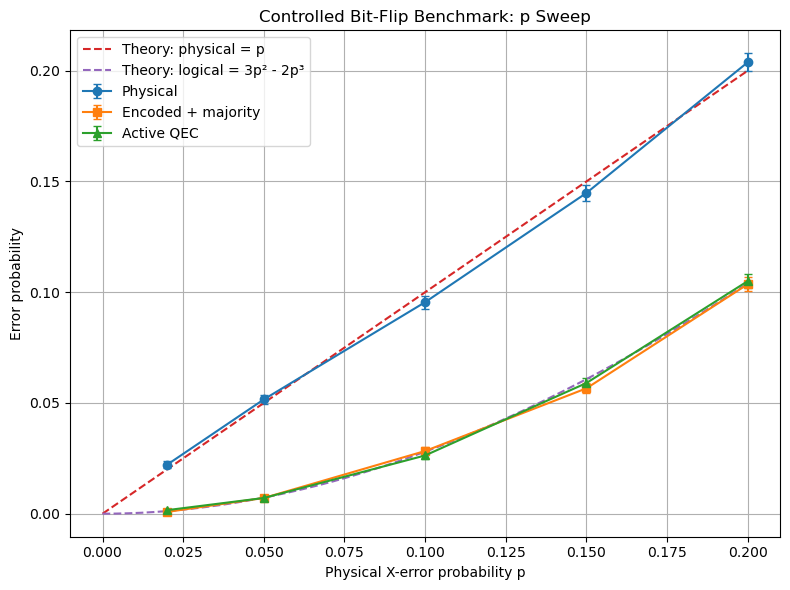

In [7]:

# ============================================================
# 7. Plot the p sweep
# ============================================================

plt.figure(figsize=(8, 6))

for kind, marker in [
    ("Physical", "o"),
    ("Encoded + majority", "s"),
    ("Active QEC", "^"),
]:
    d = p_df[p_df["kind"] == kind].sort_values("p")

    plt.errorbar(
        d["p"],
        d["error_rate"],
        yerr=d["stderr"],
        marker=marker,
        capsize=3,
        label=kind
    )

p_smooth = np.linspace(0, max(P_VALUES), 300)

plt.plot(
    p_smooth,
    p_smooth,
    linestyle="--",
    label="Theory: physical = p"
)

plt.plot(
    p_smooth,
    3*p_smooth**2 - 2*p_smooth**3,
    linestyle="--",
    label="Theory: logical = 3p² - 2p³"
)

plt.xlabel("Physical X-error probability p")
plt.ylabel("Error probability")
plt.title("Controlled Bit-Flip Benchmark: p Sweep")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()



# Part B — Multi-round error accumulation

Now fix

$$
p=0.05
$$

and vary the number of error rounds $R$.

Without active QEC:

$$
E \rightarrow E \rightarrow E \rightarrow \cdots
\rightarrow \text{final majority vote}.
$$

With active QEC:

$$
E \rightarrow QEC
\rightarrow E \rightarrow QEC
\rightarrow \cdots
\rightarrow \text{final majority vote}.
$$

This section isolates the main role of repeated correction: preventing bit-flip errors from accumulating across rounds.


In [8]:

# ============================================================
# 8. Build and run the multi-round benchmark
# ============================================================

round_records = []

for R in ROUND_VALUES:
    circuit, bits = make_no_active_qec_circuit(
        MULTI_ROUND_P,
        R
    )
    round_records.append({
        "rounds": R,
        "kind": "No active QEC",
        "circuit": circuit,
        "bits": bits,
    })

    circuit, bits = make_multi_round_active_qec_circuit(
        MULTI_ROUND_P,
        R
    )
    round_records.append({
        "rounds": R,
        "kind": "Active QEC",
        "circuit": circuit,
        "bits": bits,
    })

round_records = run_batch(
    round_records,
    "controlled-multi-round"
)


controlled-multi-round: uploaded 10 circuits
controlled-multi-round compilation: SUBMITTED
controlled-multi-round compilation: RUNNING
controlled-multi-round compilation: COMPLETED
controlled-multi-round execution: SUBMITTED
controlled-multi-round execution: RUNNING
controlled-multi-round execution: COMPLETED


In [9]:

# ============================================================
# 9. Analyse multi-round results and theory
# ============================================================

round_rows = []

for rec in round_records:
    counts = rec["result"].get_counts(rec["bits"])
    error_rate = majority_failure_rate(counts)

    stderr = np.sqrt(
        error_rate * (1.0 - error_rate) / N_SHOTS
    )

    round_rows.append({
        "rounds": rec["rounds"],
        "kind": rec["kind"],
        "error_rate": error_rate,
        "stderr": stderr,
    })

round_df = pd.DataFrame(round_rows)

q = 3*MULTI_ROUND_P**2 - 2*MULTI_ROUND_P**3

summary_rounds = []

for R in ROUND_VALUES:
    no_rate = round_df[
        (round_df["rounds"] == R) &
        (round_df["kind"] == "No active QEC")
    ]["error_rate"].iloc[0]

    active_rate = round_df[
        (round_df["rounds"] == R) &
        (round_df["kind"] == "Active QEC")
    ]["error_rate"].iloc[0]

    r_R = (
        1.0 - (1.0 - 2.0*MULTI_ROUND_P)**R
    ) / 2.0

    no_theory = 3*r_R**2 - 2*r_R**3

    active_theory = (
        1.0 - (1.0 - 2.0*q)**R
    ) / 2.0

    summary_rounds.append({
        "Rounds": R,
        "No active QEC": no_rate,
        "No active theory": no_theory,
        "Active QEC": active_rate,
        "Active theory": active_theory,
    })

summary_rounds_df = pd.DataFrame(summary_rounds)
display(summary_rounds_df)


,Rounds,No active QEC,No active theory,Active QEC,Active theory
0,1,0.0073,0.007250,0.0073,0.007250
1,2,0.0268,0.025360,0.0151,0.014395
2,3,0.0511,0.050105,0.0222,0.021436
3,5,0.1055,0.108605,0.0373,0.035214
4,10,0.2441,0.249089,0.0668,0.067948


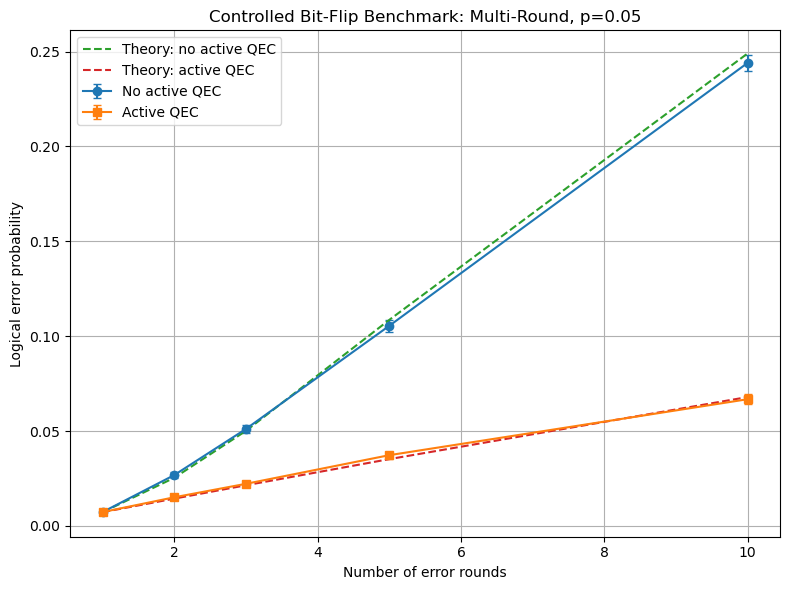

In [10]:

# ============================================================
# 10. Plot the multi-round benchmark
# ============================================================

plt.figure(figsize=(8, 6))

for kind, marker in [
    ("No active QEC", "o"),
    ("Active QEC", "s"),
]:
    d = round_df[
        round_df["kind"] == kind
    ].sort_values("rounds")

    plt.errorbar(
        d["rounds"],
        d["error_rate"],
        yerr=d["stderr"],
        marker=marker,
        capsize=3,
        label=kind
    )

plt.plot(
    summary_rounds_df["Rounds"],
    summary_rounds_df["No active theory"],
    linestyle="--",
    label="Theory: no active QEC"
)

plt.plot(
    summary_rounds_df["Rounds"],
    summary_rounds_df["Active theory"],
    linestyle="--",
    label="Theory: active QEC"
)

plt.xlabel("Number of error rounds")
plt.ylabel("Logical error probability")
plt.title(
    f"Controlled Bit-Flip Benchmark: Multi-Round, p={MULTI_ROUND_P}"
)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()



## Main takeaway

The two sections answer different questions:

- The **$p$ sweep** checks whether the implementation follows the expected repetition-code scaling $P_L=3p^2-2p^3$.
- The **multi-round benchmark** shows why active correction matters over time: repeated QEC suppresses accumulated bit-flip errors compared with waiting until the end and using only a final majority vote.

This notebook intentionally uses an $X$-only controlled noise channel. It benchmarks the repetition-code/QEC logic rather than the full H2 hardware noise model.
